# Narrative analysis (Checkpoint 5)

Produces every number and figure in the README's *Main Findings* section. Run from the repo root with `data/cdc/PAXDAY_G.xpt` and `data/cdc/DEMO_G.xpt` in place. Needs numpy, pandas, matplotlib.

Method: NHANES 2011-2012 days 2 to 8; each person is compared with their own weekdays (person fixed effects); standard errors are clustered by person; all models control for monitoring day.

In [1]:
import sys, json
sys.path.insert(0, 'analysis')
from prep import load
df, stats = load()
print(stats)
print(len(df), 'days;', df.SEQN.nunique(), 'people')
df.head()

{'pax_rows': 61168, 'pax_people': 6917, 'demo_rows': 9756, 'join_matched_people': 6917, 'pax_people_unmatched': 0, 'demo_people_without_monitor': 2839, 'days_2_8_rows': 47643, 'null_ratio_rows': 4}
47639 days; 6906 people


,SEQN,PAXDAYD,PAXDAYWD,PAXSSNDP,PAXMSTD,PAXTMD,PAXAISMD,PAXVMD,PAXMTSD,PAXWWMD,...,RIAGENDR,RIDAGEYR,RIDRETH1,INDFMPIR,DMDEDUC2,WTMEC2YR,SDMVPSU,SDMVSTRA,age_group,female
0,62161.0,2,1,3312000.0,b' 0:00:00',1440.0,3123802.0,1440.0,12531.363,816.0,...,1.0,22.0,3.0,3.15,3.0,104236.582554,1.0,91.0,18-39,0
1,62161.0,3,2,10224000.0,b' 0:00:00',1440.0,2779464.0,1440.0,14013.228,921.0,...,1.0,22.0,3.0,3.15,3.0,104236.582554,1.0,91.0,18-39,0
2,62161.0,4,3,17136000.0,b' 0:00:00',1440.0,2724602.0,1440.0,16982.386,911.0,...,1.0,22.0,3.0,3.15,3.0,104236.582554,1.0,91.0,18-39,0
3,62161.0,5,4,24048000.0,b' 0:00:00',1440.0,3144826.0,1440.0,11718.500,854.0,...,1.0,22.0,3.0,3.15,3.0,104236.582554,1.0,91.0,18-39,0
4,62161.0,6,5,30960000.0,b' 0:00:00',1440.0,3001421.0,1440.0,16184.914,949.0,...,1.0,22.0,3.0,3.15,3.0,104236.582554,1.0,91.0,18-39,0


## Run all analyses and save figures

This writes `results/narrative_results.json` and `figures/finding-one.png`, `finding-two.png`, `finding-three.png`.

In [2]:
%run analysis/narrative_results.py

saved results/narrative_results.json


In [3]:
R = json.load(open('results/narrative_results.json'))
fmt = lambda d: f"{d['coef']:.2f} [{d['lo']:.2f}, {d['hi']:.2f}]"
for k, v in R['finding1'].items(): print('F1', k, fmt(v))

F1 mims_per_min_unadjusted -0.75 [-0.82, -0.68]
F1 mims_per_min -0.57 [-0.63, -0.50]
F1 daily_mims -816.49 [-911.15, -721.82]
F1 m_awake -0.13 [-0.21, -0.06]
F1 awake_min -41.95 [-46.19, -37.70]
F1 sleep_min 19.63 [15.99, 23.27]
F1 nonwear_min 21.95 [16.75, 27.15]
F1 mims_per_min_controlling_sleep_nonwear -0.11 [-0.16, -0.07]


## Finding 1: weekends differ in time more than in movement rate

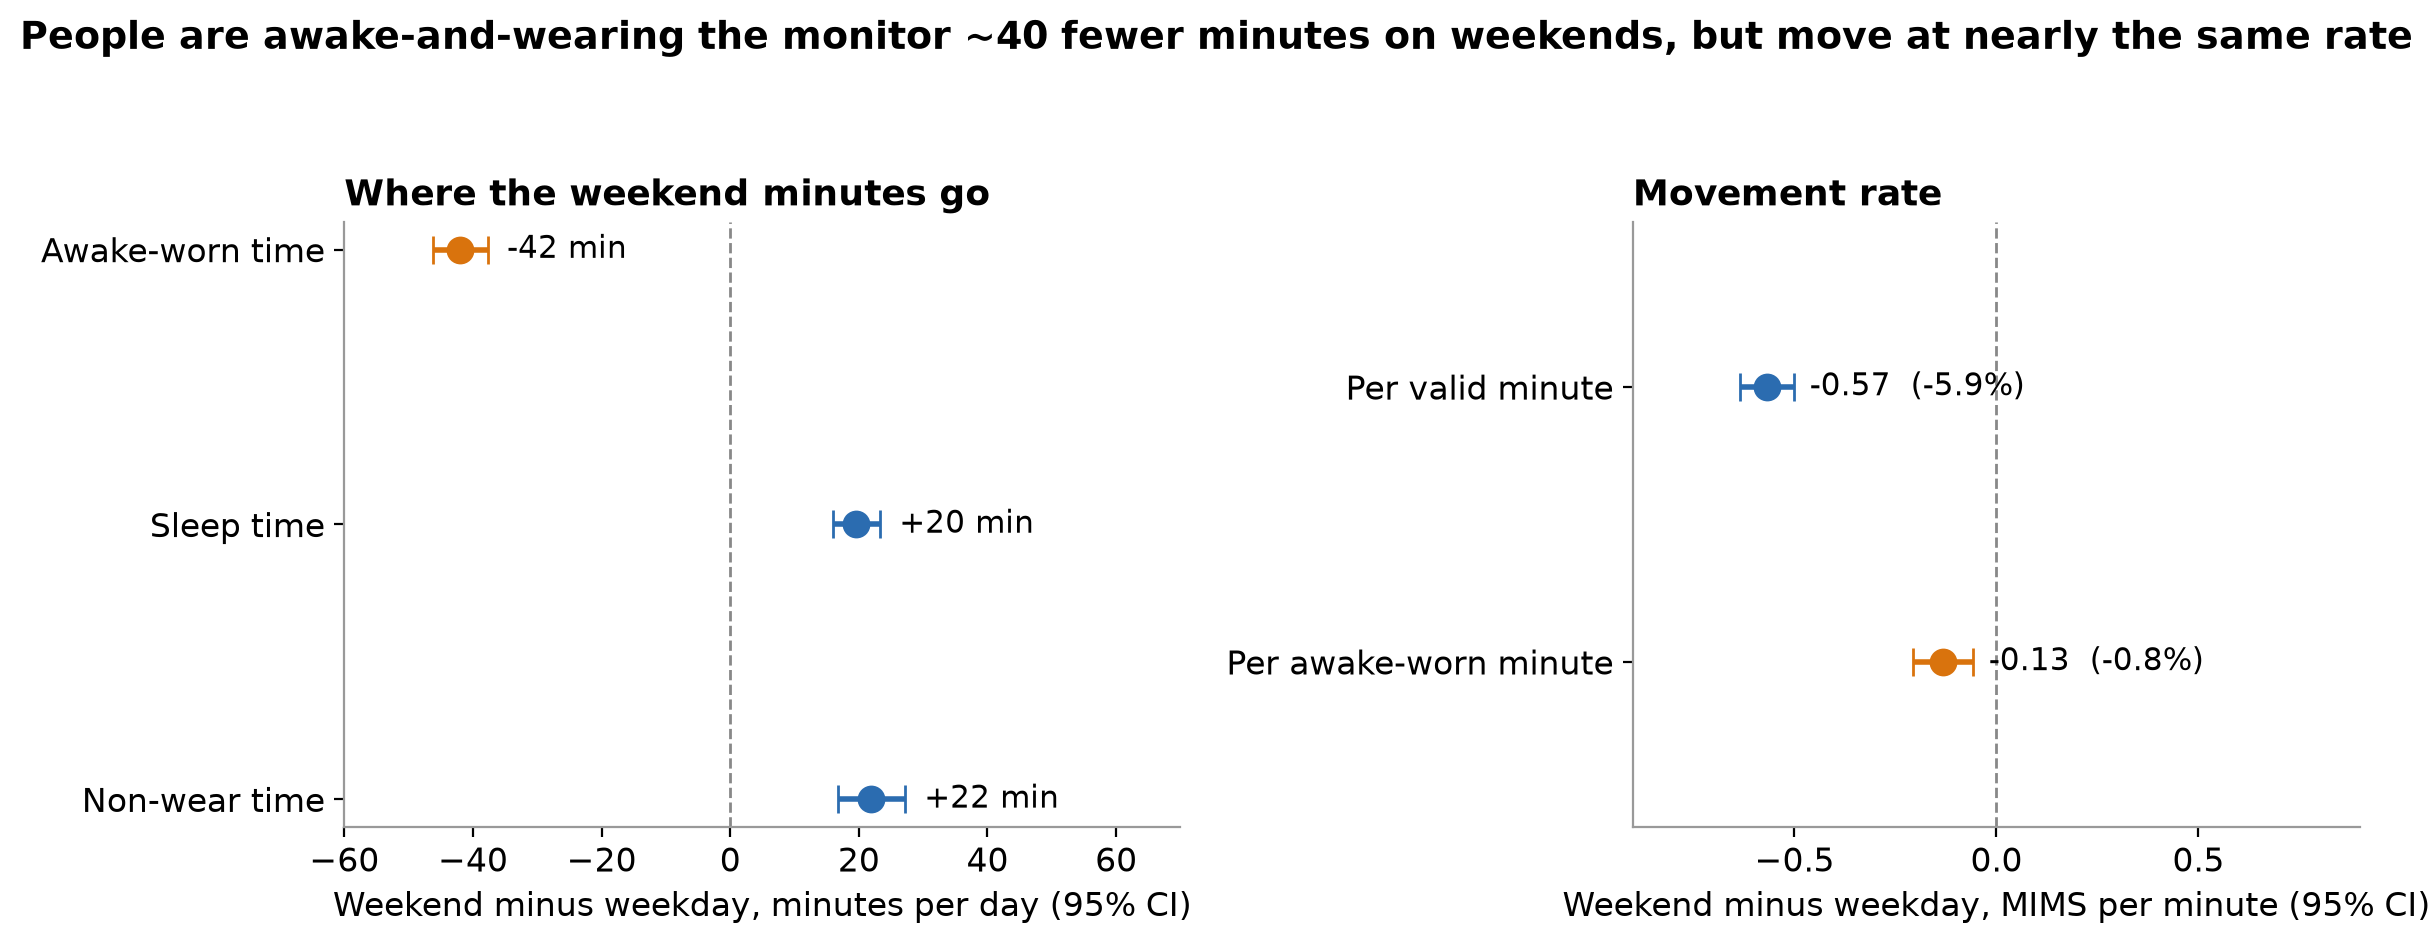

In [4]:
from IPython.display import Image
Image('figures/finding-one.png')

In [5]:
for k, v in R['finding1_checks_m_awake'].items(): print('check', k, fmt(v))
print({k: fmt(v) for k, v in R['monitoring_day_effects_mims_per_min'].items()})

check valid>=1200 min -0.13 [-0.20, -0.05]
check awake>=600 min -0.13 [-0.21, -0.06]
check Fridays dropped -0.09 [-0.17, -0.02]
check survey-weighted 0.01 [-0.08, 0.11]
check controlling for sleep minutes -0.09 [-0.17, -0.02]
{'d3': '0.05 [-0.03, 0.12]', 'd4': '-0.13 [-0.21, -0.05]', 'd5': '-0.30 [-0.39, -0.22]', 'd6': '-0.38 [-0.47, -0.29]', 'd7': '-0.57 [-0.66, -0.47]', 'd8': '-1.35 [-1.46, -1.25]'}


## Finding 2: the time shift depends on age

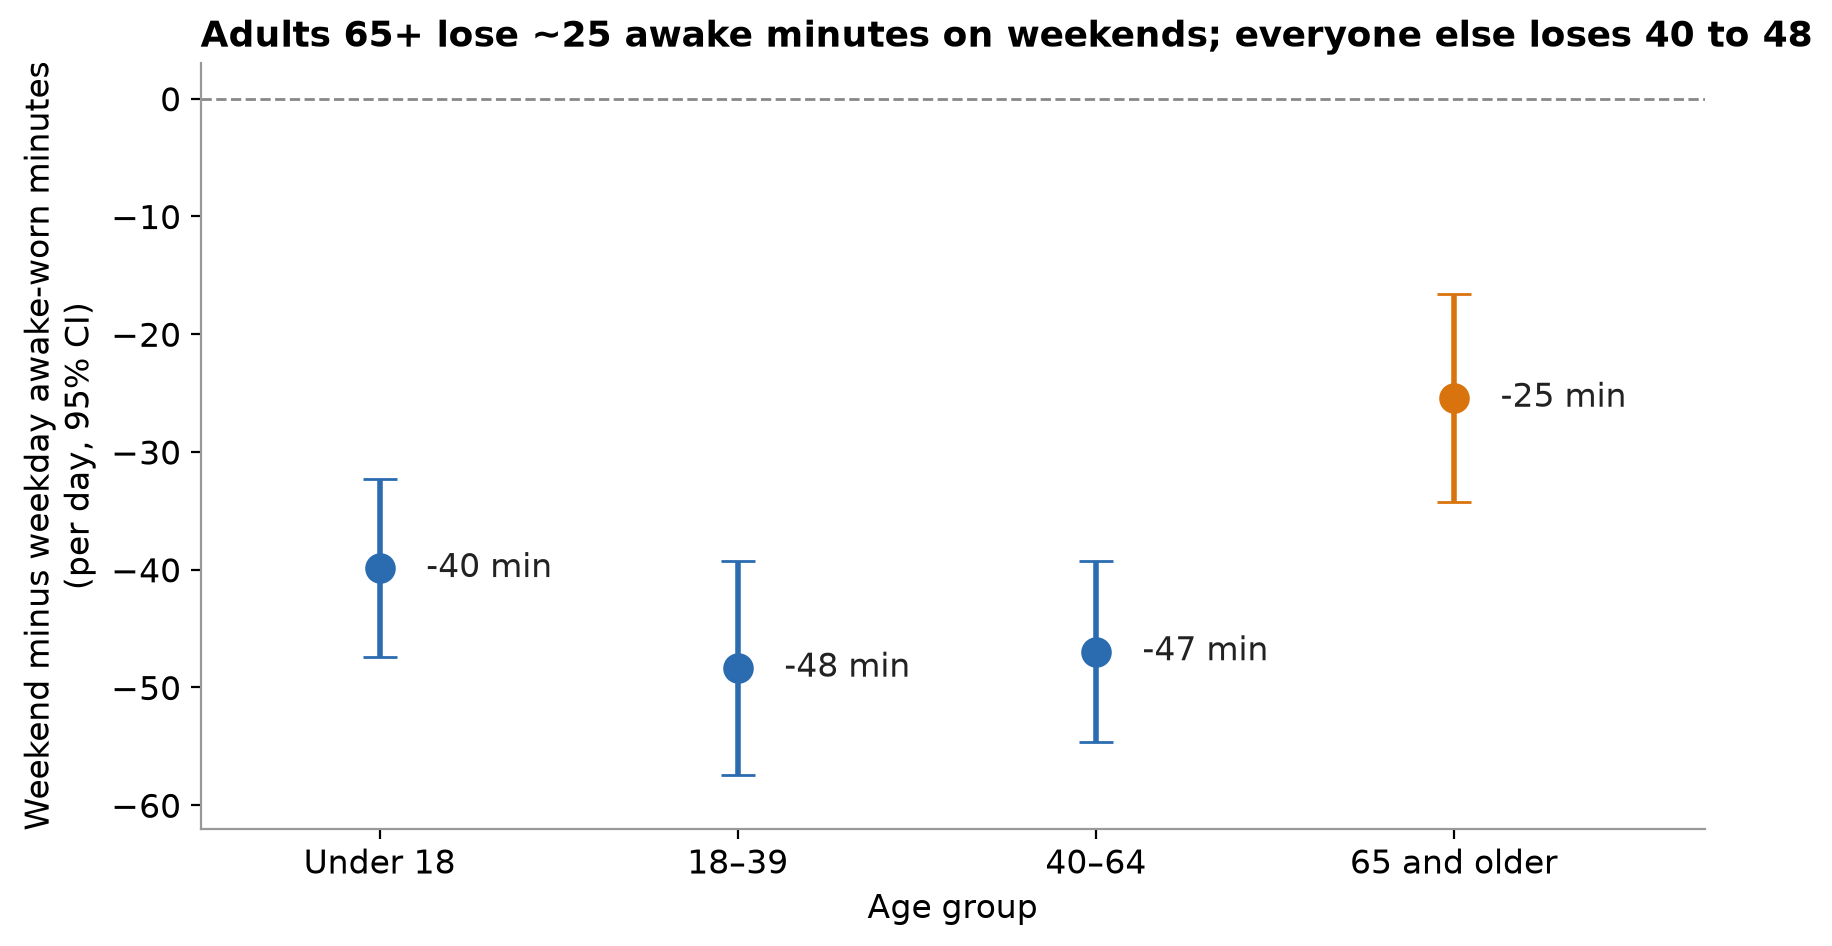

In [6]:
Image('figures/finding-two.png')

In [7]:
print({g: fmt(v) for g, v in R['finding2']['awake_min'].items()})
print('65+ vs under 65:', fmt(R['finding2_65_vs_under65_awake_min']))
print('weighted:', fmt(R['finding2_65_vs_under65_awake_min_weighted']))
print('>=1200 valid min:', fmt(R['finding2_65_vs_under65_awake_min_valid1200']))

{'<18': '-39.89 [-47.45, -32.33]', '18-39': '-48.35 [-57.47, -39.22]', '40-64': '-46.95 [-54.66, -39.25]', '65+': '-25.43 [-34.26, -16.60]'}
65+ vs under 65: 19.63 [9.58, 29.67]
weighted: 21.22 [8.92, 33.52]
>=1200 valid min: 17.80 [8.03, 27.56]


## Finding 3: the effort shift depends on sex and income

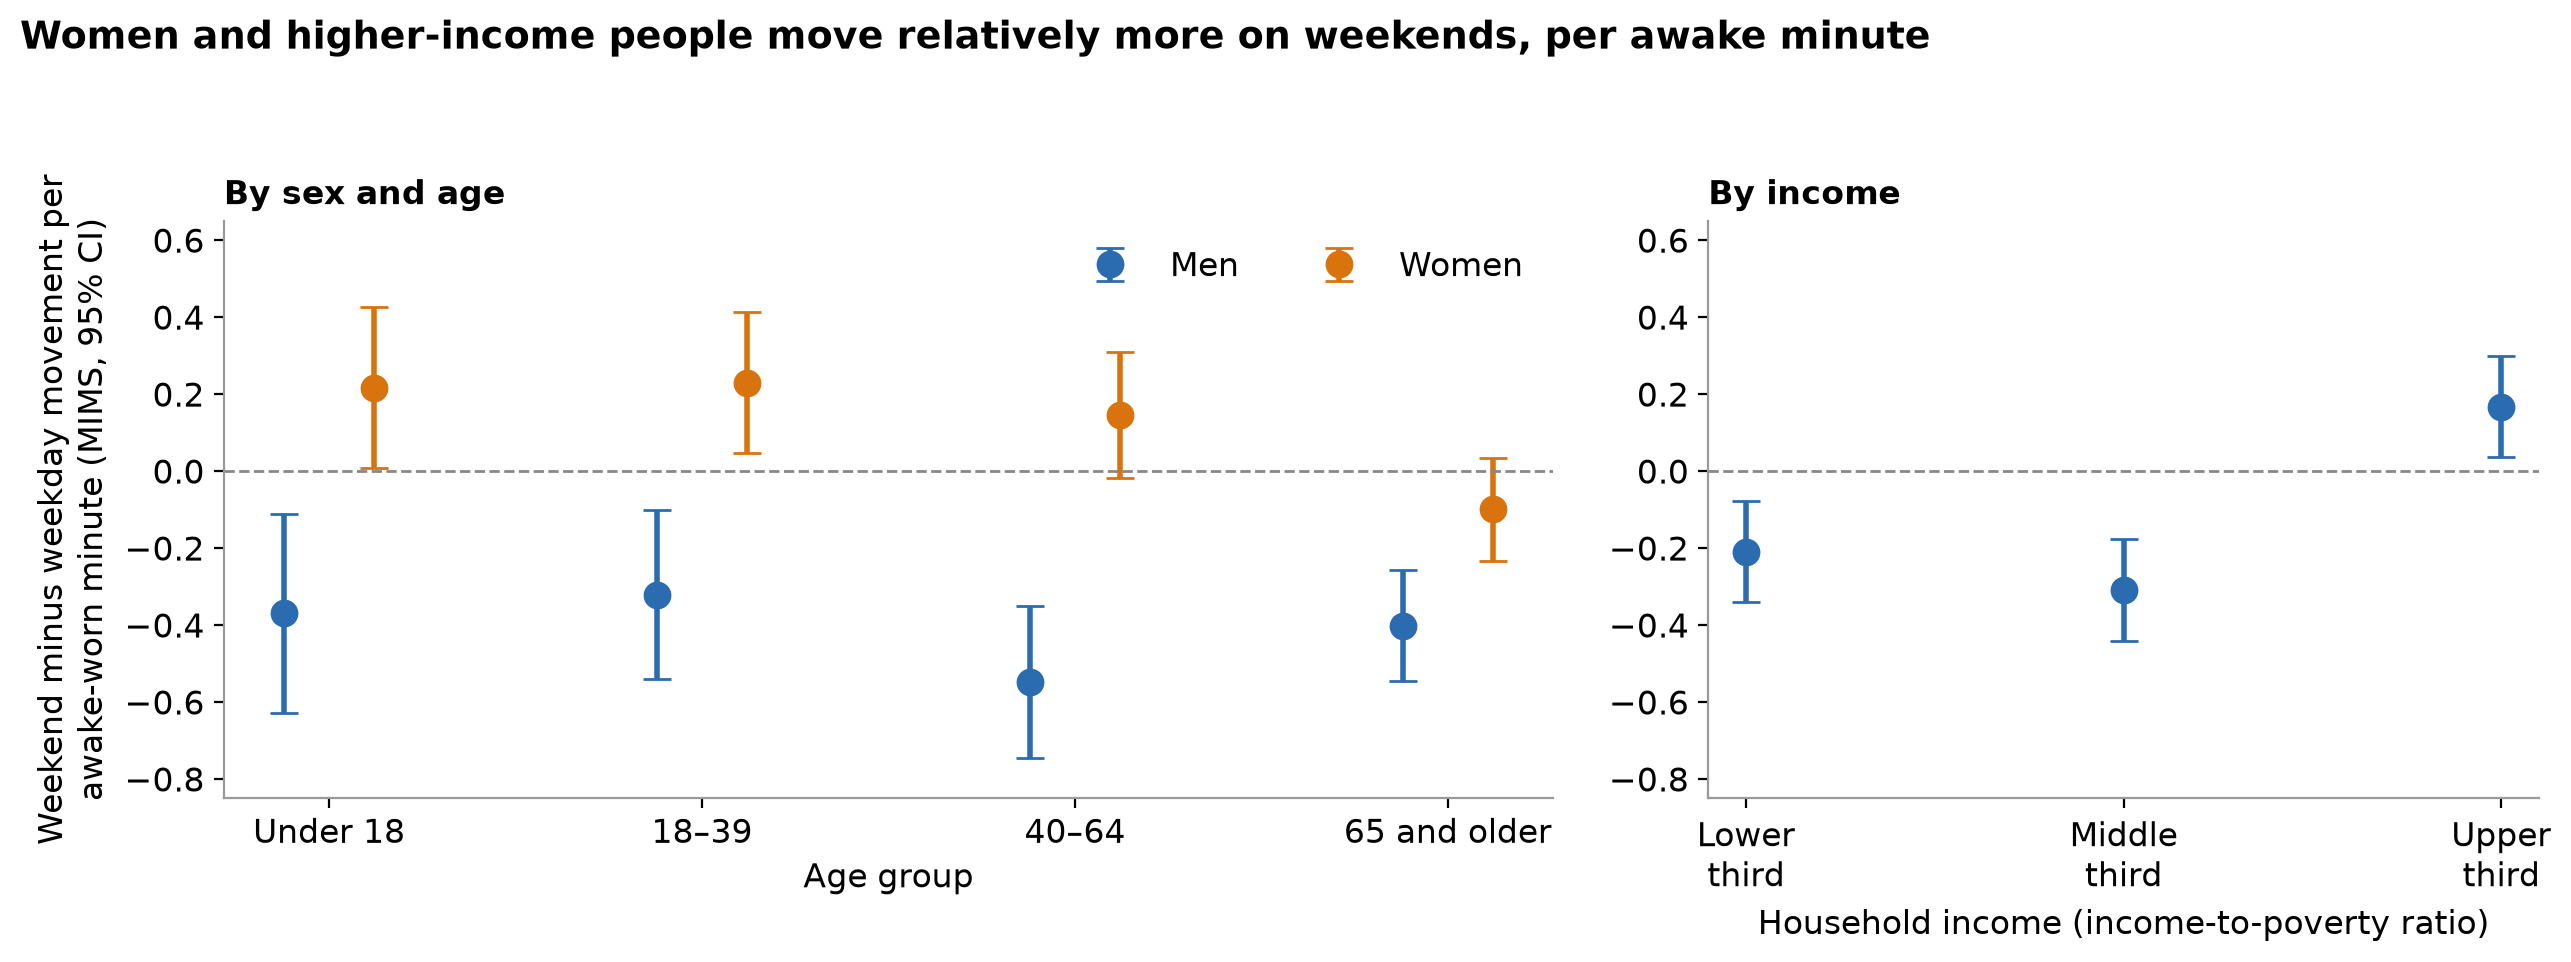

In [8]:
Image('figures/finding-three.png')

In [9]:
print({k: fmt(v) for k, v in R['finding3_by_sex_m_awake'].items()})
print('joint:', {k: (fmt(v) if isinstance(v, dict) else v) for k, v in R['finding3_joint_m_awake'].items()})
print({k: fmt(v) for k, v in R['finding3_women_minus_men'].items()})
print({k: fmt(v) for k, v in R['finding3_income_tertiles_m_awake'].items()})

{'Men': '-0.40 [-0.52, -0.29]', 'Women': '0.13 [0.04, 0.23]'}
joint: {'women_minus_men': '0.59 [0.44, 0.74]', 'per_unit_income_ratio': '0.14 [0.09, 0.19]', 'n_people': 6281}
{'unadjusted_for_age': '0.56 [0.42, 0.71]', 'valid>=1200': '0.56 [0.41, 0.70]', 'awake>=600': '0.61 [0.46, 0.76]', 'controlling sleep minutes': '0.57 [0.42, 0.71]', 'survey-weighted': '0.60 [0.40, 0.79]'}
{'Lower third': '-0.21 [-0.34, -0.08]', 'Middle third': '-0.31 [-0.44, -0.18]', 'Upper third': '0.17 [0.04, 0.30]'}


## Cross-check: mixed-effects model (random intercept per person)

A mixed-effects model, `outcome ~ weekend + ... + (1 | SEQN)`, also gives each person their own baseline, but treats those baselines as draws from a distribution instead of fitting one per person. It answers the same within-person question as the fixed-effects regression used above, so its weekend coefficients should be close to the main estimates. This cell requires **statsmodels**; if it is not installed, the cell prints a message and skips.

In [10]:
try:
    import statsmodels.formula.api as smf
    import numpy as np
    d = df.copy()
    d['awake'] = np.where(d.PAXWWMD >= 300, d.PAXMTSD / d.PAXWWMD.where(d.PAXWWMD > 0), np.nan)
    d = d.dropna(subset=['awake', 'mims_per_min'])
    m = smf.mixedlm('mims_per_min ~ weekend + C(PAXDAYD) + C(age_group) + female + INDFMPIR', d.dropna(subset=['INDFMPIR']), groups='SEQN').fit()
    print(m.summary())
    m2 = smf.mixedlm('awake ~ weekend + C(PAXDAYD) + C(age_group) + female + INDFMPIR', d.dropna(subset=['INDFMPIR']), groups='SEQN').fit()
    print(m2.summary())
except ImportError:
    print('statsmodels not installed; skipping the mixed-model cross-check')

              Mixed Linear Model Regression Results
Model:               MixedLM   Dependent Variable:   mims_per_min
No. Observations:    41051     Method:               REML        
No. Groups:          6281      Scale:                4.2532      
Min. group size:     1         Log-Likelihood:       -95366.1450 
Max. group size:     7         Converged:            Yes         
Mean group size:     6.5                                         
-----------------------------------------------------------------
                      Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-----------------------------------------------------------------
Intercept             12.324    0.086 143.201 0.000 12.155 12.492
C(PAXDAYD)[T.3]        0.078    0.038   2.067 0.039  0.004  0.151
C(PAXDAYD)[T.4]        0.009    0.038   0.236 0.813 -0.065  0.083
C(PAXDAYD)[T.5]       -0.068    0.038  -1.792 0.073 -0.143  0.006
C(PAXDAYD)[T.6]       -0.089    0.038  -2.335 0.020 -0.163 -0.014
C(PAXDAYD)[T.7]       -0